In [ ]:
import torch

if torch.cuda.is_available():
    print("GPU 已成功啟用！")
    print("GPU 型號：", torch.cuda.get_device_name(0))
else:
    print("目前使用 CPU，尚未啟用 GPU")


GPU 已成功啟用！
GPU 型號： Tesla T4


In [ ]:
!pip install -q gradio ultralytics

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO

# 載入 YOLO 預訓練模型
model = YOLO("yolo26n.pt")

print("YOLO 模型載入成功！")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO 模型載入成功！


In [ ]:
# 使用 YOLO 偵測一張範例圖片
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    save=True,
    conf=0.25
)

print("圖片辨識完成！")


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 16.3ms
Speed: 106.5ms preprocess, 16.3ms inference, 42.0ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict
圖片辨識完成！


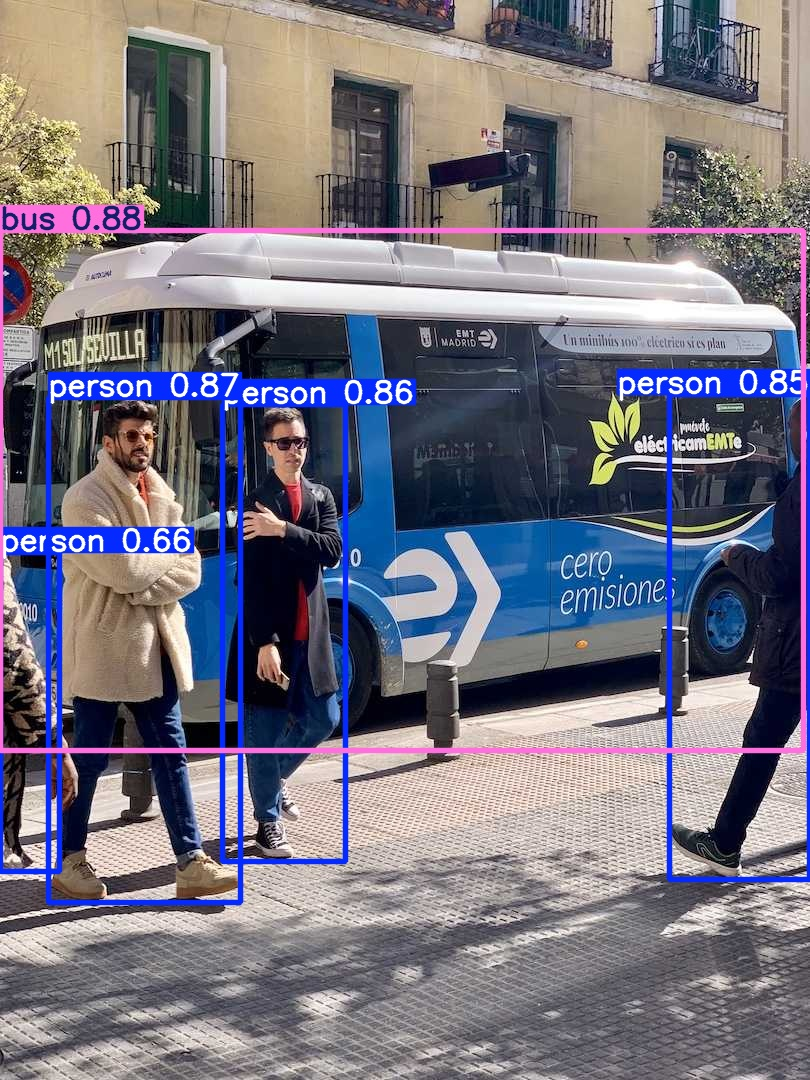

In [ ]:
from IPython.display import Image, display
from pathlib import Path

# 找出剛才儲存的辨識圖片
image_path = Path(results[0].save_dir) / "bus.jpg"

display(Image(filename=str(image_path)))

#初版YOLO


In [ ]:
from ultralytics import YOLO

# 載入預訓練模型
model = YOLO("yolo26n.pt")

# 開始訓練
train_results = model.train(
    data="coco8.yaml",
    epochs=5,
    imgsz=640,
    batch=4,
    device=0,
    name="yolo_beginner"
)

print("YOLO 訓練完成！")

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_beginner, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, ove

訓練結果資料夾： /content/runs/detect/yolo_beginner


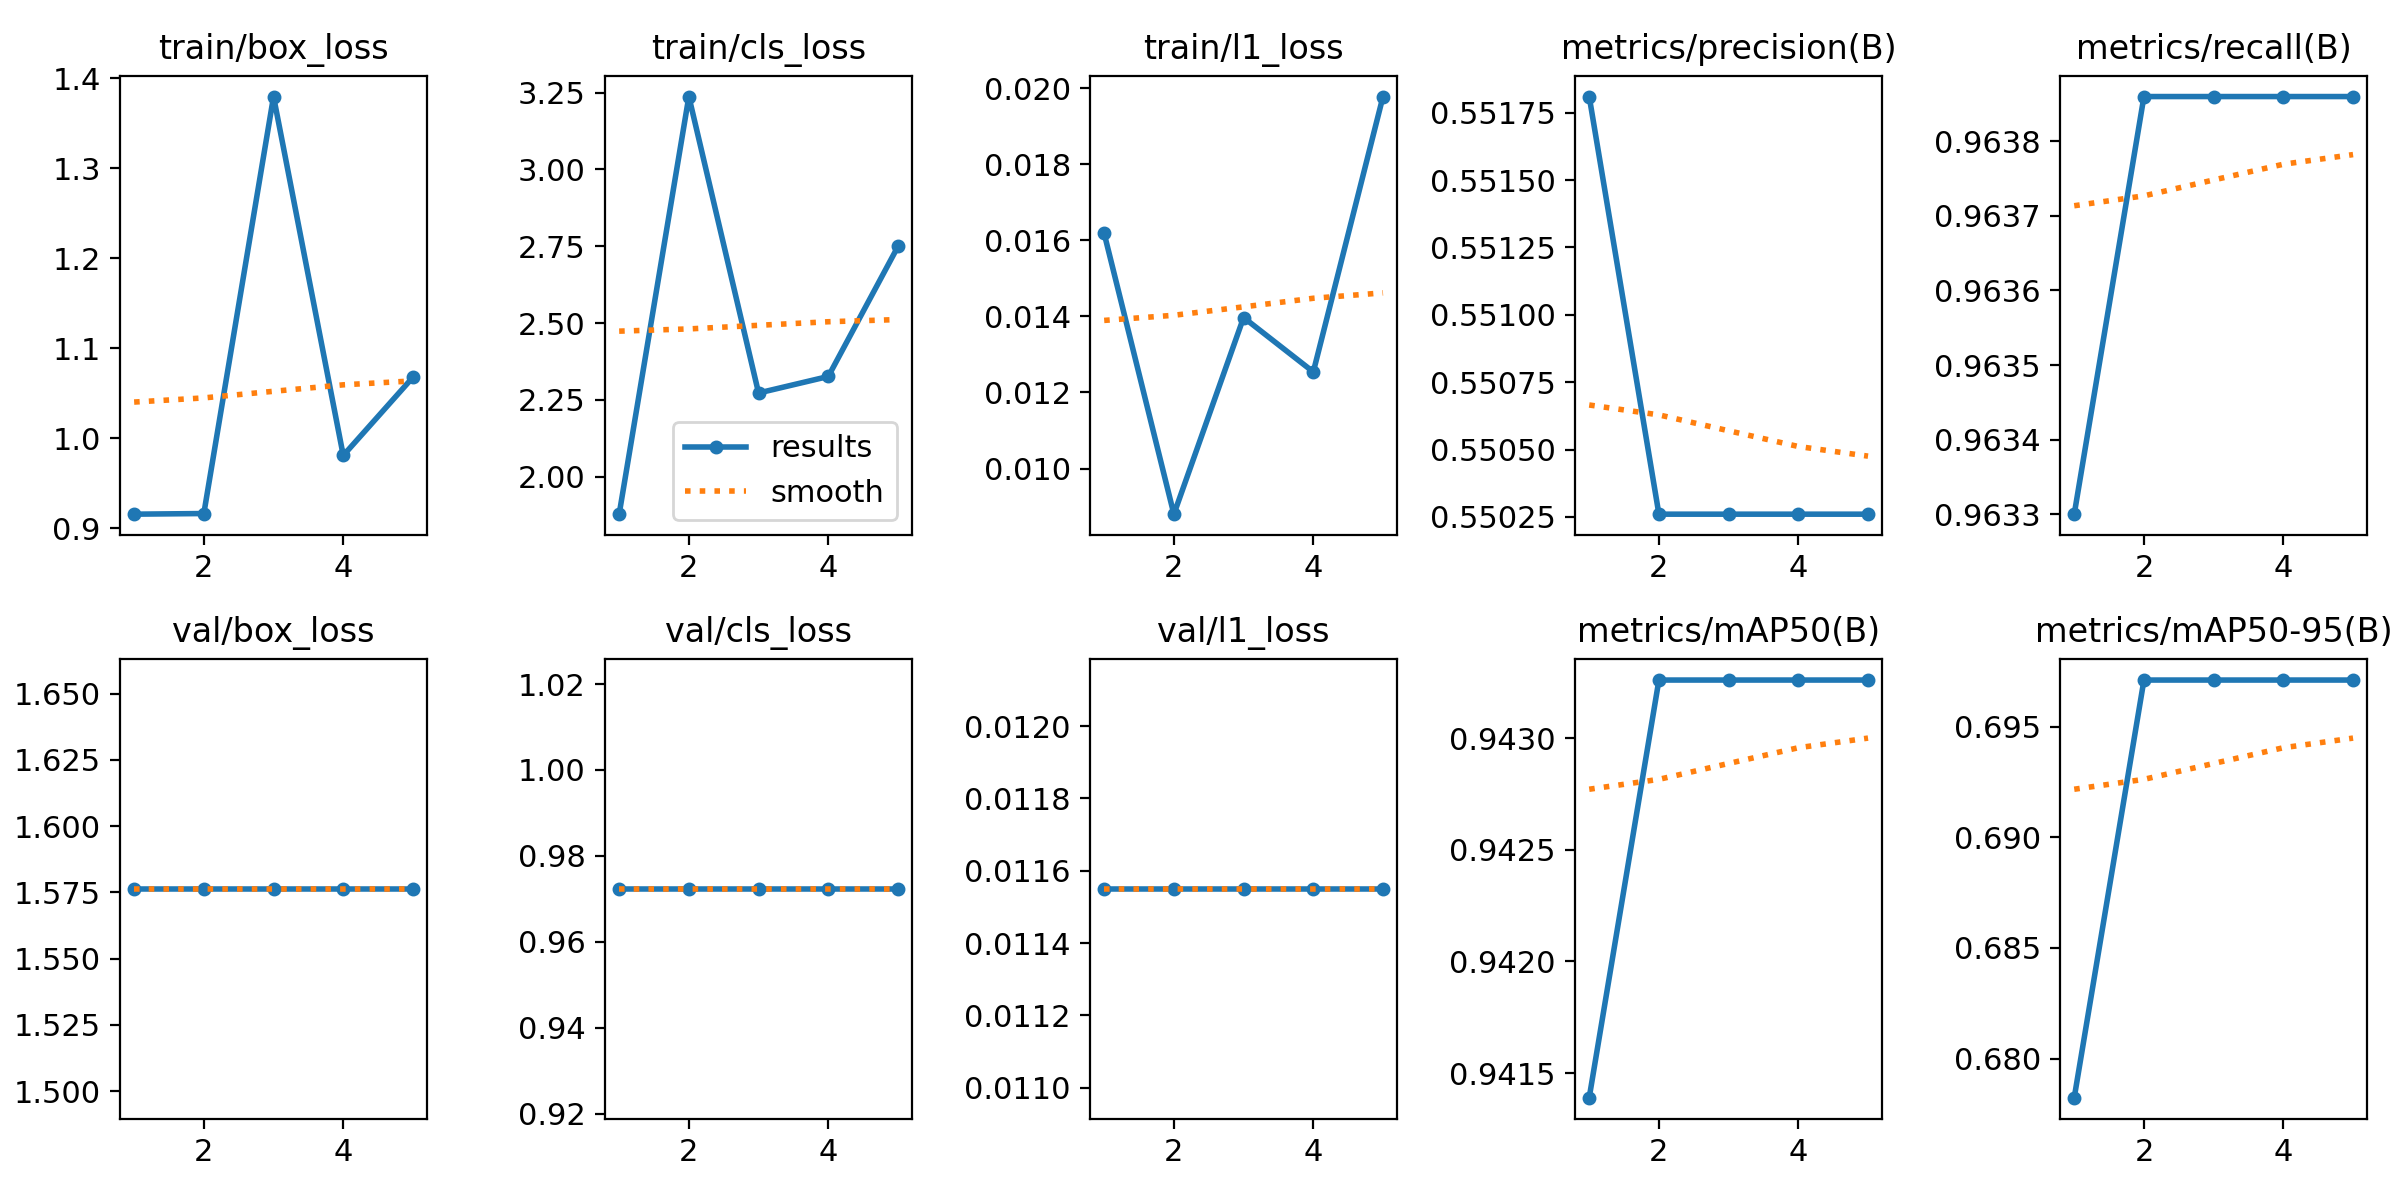

In [ ]:
from pathlib import Path
from IPython.display import display, Image

# 取得本次訓練的資料夾
save_dir = Path(model.trainer.save_dir)

print("訓練結果資料夾：", save_dir)

# 顯示訓練曲線
results_image = save_dir / "results.png"

if results_image.exists():
    display(Image(filename=str(results_image)))
else:
    print("找不到 results.png，請檢查訓練是否完成。")

找到模型： /content/runs/detect/yolo_beginner/weights/best.pt

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 9.1ms
Speed: 1.8ms preprocess, 9.1ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict-2


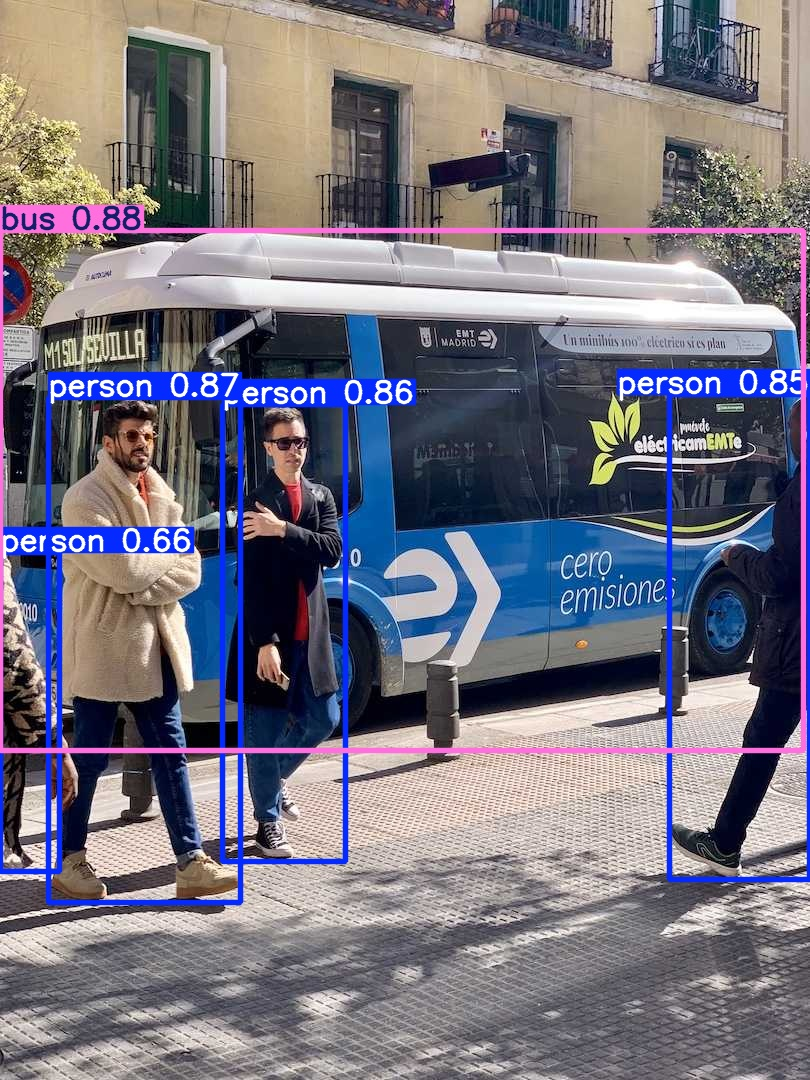

訓練後的模型已完成預測！


In [ ]:
from ultralytics import YOLO
from IPython.display import display, Image
from pathlib import Path
import glob

# 尋找訓練產生的最佳模型
model_files = glob.glob(
    "/content/runs/detect/**/weights/best.pt",
    recursive=True
)

if not model_files:
    raise FileNotFoundError(
        "找不到 best.pt，請確認步驟 11 的訓練是否成功完成。"
    )

# 使用最近修改的模型檔案
best_model_path = max(model_files, key=lambda p: Path(p).stat().st_mtime)

print("找到模型：", best_model_path)

# 載入訓練後的模型
best_model = YOLO(best_model_path)

# 使用模型辨識範例圖片
results = best_model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    save=True,
    conf=0.25
)

# 顯示辨識結果
result_image = Path(results[0].save_dir) / "bus.jpg"

if result_image.exists():
    display(Image(filename=str(result_image)))
else:
    print("找不到輸出的圖片，請檢查預測結果。")

print("訓練後的模型已完成預測！")

In [ ]:
from google.colab import files

files.download(str(best_model_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO

# 載入 best.pt
model = YOLO("/content/best.pt")

print("best.pt 載入成功！")

best.pt 載入成功！


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving best.pt to best (1).pt


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/my_dataset"

for folder in [
    "images/train",
    "images/val",
    "labels/train",
    "labels/val"
]:
    os.makedirs(os.path.join(dataset_path, folder), exist_ok=True)

print("Dataset 資料夾已準備完成！")

Dataset 資料夾已準備完成！


#新設計YOLO

In [ ]:
import os

# 請確保路徑名稱與你在 Google Drive 中的資料夾名稱一致 (例如 my_dataset 或 Dataset)
DATASET_PATH = "/content/drive/MyDrive/my_dataset"

yaml_content = f"""path: {DATASET_PATH}
train: images/train
val: images/val

nc: 7
names:
  0: person
  1: milk
  2: cup
  3: Cow
  4: car
  5: bus
  6: 機車
  """
yaml_path = os.path.join(DATASET_PATH, "data.yaml")

# 確保資料夾路徑存在後再寫入
os.makedirs(DATASET_PATH, exist_ok=True)

with open(yaml_path, "w", encoding="utf-8") as f:
    f.write(yaml_content)

print("data.yaml 已成功建立/覆蓋：", yaml_path)

# 印出檔案內容確認格式無誤
with open(yaml_path, "r", encoding="utf-8") as f:
    print("\n--- data.yaml 內容 ---")
    print(f.read())

data.yaml 已成功建立/覆蓋： /content/drive/MyDrive/my_dataset/data.yaml

--- data.yaml 內容 ---
path: /content/drive/MyDrive/my_dataset
train: images/train
val: images/val

nc: 7
names:
  0: person
  1: milk
  2: cup
  3: Cow
  4: car
  5: bus
  6: 機車
  


In [ ]:
import os

base_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base_path):
    if os.path.basename(root).lower() == "dataset":
        print("找到 Dataset：", root)
        print("裡面的檔案：", os.listdir(root))

In [ ]:
!pip install -q ultralytics

In [ ]:
from google.colab import drive
from ultralytics import YOLO

# 1. 掛載 Google Drive (若已掛載可跳過)
drive.mount('/content/drive')

# 2. 載入模型 (以 YOLOv8 輕量版為例)
model = YOLO('yolov8n.pt')

# 3. 開始訓練
results = model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    project=f"{DATASET_PATH}/runs",
    name="exp1"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/my_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, 

/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py:783: UserWarning: Glyph 27231 (\N{CJK UNIFIED IDEOGRAPH-6A5F}) missing from font(s) DejaVu Sans.
  plt.savefig(fname, dpi=200)
/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py:783: UserWarning: Glyph 36554 (\N{CJK UNIFIED IDEOGRAPH-8ECA}) missing from font(s) DejaVu Sans.
  plt.savefig(fname, dpi=200)
/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py:783: UserWarning: Glyph 27231 (\N{CJK UNIFIED IDEOGRAPH-6A5F}) missing from font(s) DejaVu Sans.
  plt.savefig(fname, dpi=200)
/usr/local/lib/python3.13/dist-packages/ultralytics/utils/plotting.py:783: UserWarning: Glyph 36554 (\N{CJK UNIFIED IDEOGRAPH-8ECA}) missing from font(s) DejaVu Sans.
  plt.savefig(fname, dpi=200)


Using 6 train, 7 val images for fraction=1.0 at imgsz=640
Using 0 dataloader workers
Logging results to /content/drive/MyDrive/my_dataset/runs/exp1
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/50     0.879G      2.024      6.269      2.522         12        640: 100% ━━━━━━━━━━━━ 1/1 1.7it/s 0.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.9it/s 0.3s
                   all          7          7      0.226      0.429      0.129      0.103

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50     0.916G      1.281      4.633      1.707         21        640: 100% ━━━━━━━━━━━━ 1/1 7.5it/s 0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.7it/s 0.1s
                   all          7          7      0.226      0.429      0.129      0.103

  

/usr/local/lib/python3.13/dist-packages/ultralytics/utils/metrics.py:712: UserWarning: Glyph 27231 (\N{CJK UNIFIED IDEOGRAPH-6A5F}) missing from font(s) DejaVu Sans.
  fig.savefig(save_dir, dpi=250)
/usr/local/lib/python3.13/dist-packages/ultralytics/utils/metrics.py:712: UserWarning: Glyph 36554 (\N{CJK UNIFIED IDEOGRAPH-8ECA}) missing from font(s) DejaVu Sans.
  fig.savefig(save_dir, dpi=250)
/usr/local/lib/python3.13/dist-packages/ultralytics/utils/metrics.py:760: UserWarning: Glyph 27231 (\N{CJK UNIFIED IDEOGRAPH-6A5F}) missing from font(s) DejaVu Sans.
  fig.savefig(save_dir, dpi=250)
/usr/local/lib/python3.13/dist-packages/ultralytics/utils/metrics.py:760: UserWarning: Glyph 36554 (\N{CJK UNIFIED IDEOGRAPH-8ECA}) missing from font(s) DejaVu Sans.
  fig.savefig(save_dir, dpi=250)
/usr/local/lib/python3.13/dist-packages/ultralytics/utils/metrics.py:760: UserWarning: Glyph 27231 (\N{CJK UNIFIED IDEOGRAPH-6A5F}) missing from font(s) DejaVu Sans.
  fig.savefig(save_dir, dpi=250)
/usr/

                   all          7          7      0.718      0.571      0.712      0.477
                person          1          1          1          0      0.995      0.398
                  milk          1          1          1          0    0.00575    0.00345
                   cup          1          1      0.695          1      0.995      0.895
                   Cow          1          1          0          0          0          0
                   car          1          1      0.783          1      0.995      0.697
                   bus          1          1      0.632          1      0.995      0.697
                    機車          1          1      0.914          1      0.995      0.647
Speed: 0.2ms preprocess, 25.0ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/drive/MyDrive/my_dataset/runs/exp1


In [ ]:
import gradio as gr
from ultralytics import YOLO
from PIL import Image

# 載入模型 (若在 Colab 可使用 uploaded，否則使用預設路徑 'best.pt')
try:
    model_path = next(iter(uploaded))
except NameError:
    model_path = 'best.pt'

model = YOLO(model_path)
print("YOLO 模型載入成功！")

def detect_image(image):
    if image is None:
        return None, "請先上傳圖片。"

    # 執行 YOLO 辨識
    results = model.predict(
        source=image,
        conf=0.25,
        imgsz=640,
        verbose=False
    )

    result = results[0]

    # 繪製辨識結果圖 (BGR 轉 RGB)
    annotated_image = result.plot()
    annotated_image = annotated_image[:, :, ::-1]
    output_image = Image.fromarray(annotated_image)

    # 整理文字資訊
    if len(result.boxes) == 0:
        information = "沒有偵測到符合條件的物品。"
    else:
        names = result.names
        detected_items = []

        for box in result.boxes:
            class_id = int(box.cls[0])
            class_name = names[class_id]
            detected_items.append(class_name)

        information = f"共偵測到 {len(detected_items)} 個物件：\n\n"

        for index, item in enumerate(detected_items, start=1):
            information += f"{index}. {item}\n"

    return output_image, information


# 建立 Gradio 介面
with gr.Blocks(title="YOLO AI 物件辨識系統", theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # 🔍 YOLO AI 物件辨識系統

        歡迎使用本系統！

        上傳一張圖片，系統將使用 YOLO 模型進行物件辨識，
        並顯示辨識框與物品名稱。
        """
    )

    with gr.Row():

        with gr.Column(scale=1):
            input_image = gr.Image(
                type="pil",
                label="請上傳要辨識的圖片"
            )

            detect_button = gr.Button(
                "🚀 開始辨識",
                variant="primary"
            )

        with gr.Column(scale=1):
            output_image = gr.Image(
                type="pil",
                label="辨識結果"
            )

            output_text = gr.Textbox(
                label="辨識資訊",
                lines=8
            )

    detect_button.click(
        fn=detect_image,
        inputs=input_image,
        outputs=[output_image, output_text]
    )

demo.launch(share=True)

YOLO 模型載入成功！


/tmp/ipykernel_521/716718583.py:54: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="YOLO AI 物件辨識系統", theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1398d5e5ad12aa1242.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
